MY INFLATION CALCULATOR WITH BANK OF CANADA DATA: PART 1 THE GRAPH

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

#read the cpi data from the csv file
data_frame = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8) #data starts at row 9, we skip the first 8 rows
data_frame = data_frame.rename(columns={'STATIC_INFLATIONCALC': 'CPI'}) #rename the column to 'CPI' for clarity

# I'm checkingg the first and last rows to make sure the data loaded properly
print(data_frame.head(15)) 
print(data_frame.tail(5))

          date  CPI
0   1914-01-01  6.0
1   1914-02-01  6.0
2   1914-03-01  6.0
3   1914-04-01  6.0
4   1914-05-01  5.9
5   1914-06-01  6.0
6   1914-07-01  5.9
7   1914-08-01  6.0
8   1914-09-01  6.0
9   1914-10-01  6.1
10  1914-11-01  6.1
11  1914-12-01  6.1
12  1915-01-01  6.1
13  1915-02-01  6.1
14  1915-03-01  6.1
            date    CPI
1350  2026-05-01  169.6
1351  2026-06-01  169.0
1352  2026-07-01  169.9
1353  2026-08-01  169.8
1354  2026-09-01  170.0


In [58]:
# Removing the two odd rows (1927-04-30 and 1932-04-30) - they are duplicates of May
data_frame = data_frame[data_frame['date'] != '1927-04-30']
data_frame = data_frame[data_frame['date'] != '1932-04-30']
data_frame = data_frame.reset_index(drop=True) #After removing rows, row numbers have gaps; Renumber them 0, 1, 2, …

# Turn the date column into real dates (instead of plain text) - i referenced chapter 6 of TPB
data_frame['date'] = pd.to_datetime(data_frame['date'])

# Annual % change: compare each month to the same month one year (12 rows) earlier
# I looked up pct_change in the pandas documentation - pct_change(12) compares
# each value to the value 12 rows before it, which is the same month last year
data_frame['Annual Change (%)'] = data_frame['CPI'].pct_change(12) * 100

#Checking to see the data is loaded properly and the annual change is calculated correctly
print(data_frame.head(14))
print(data_frame.tail(3))
print(len(data_frame))

         date  CPI  Annual Change (%)
0  1914-01-01  6.0                NaN
1  1914-02-01  6.0                NaN
2  1914-03-01  6.0                NaN
3  1914-04-01  6.0                NaN
4  1914-05-01  5.9                NaN
5  1914-06-01  6.0                NaN
6  1914-07-01  5.9                NaN
7  1914-08-01  6.0                NaN
8  1914-09-01  6.0                NaN
9  1914-10-01  6.1                NaN
10 1914-11-01  6.1                NaN
11 1914-12-01  6.1                NaN
12 1915-01-01  6.1           1.666667
13 1915-02-01  6.1           1.666667
           date    CPI  Annual Change (%)
1350 2026-07-01  169.9           3.032141
1351 2026-08-01  169.8           3.033981
1352 2026-09-01  170.0           3.092784
1353


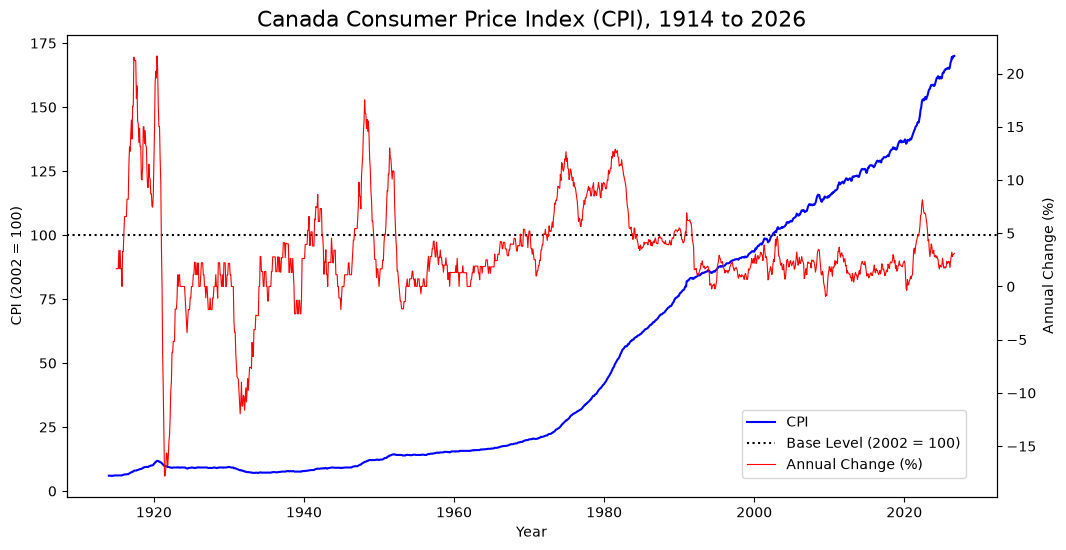

In [59]:
# NOW, let's plot the data. We will plot the CPI on the left axis and the annual % change on the right axis.


# Create the figure (Learned in Lecture 7)
fig, ax = plt.subplots(figsize=(12, 6))

# Plot the CPI on the left axis
ax.plot(data_frame['date'], data_frame['CPI'], color='blue', label='CPI')

# Creating a horizontal dotted line to represent the base level (2002 = 100)
ax.axhline(100, color='black', linestyle=':', label='Base Level (2002 = 100)')

# Create a second y-axis on the right side for the annual % change
ax2 = ax.twinx()
ax2.plot(data_frame['date'], data_frame['Annual Change (%)'], color='red', linewidth=0.8, label='Annual Change (%)')

# Title and axis labels
ax.set_title('Canada Consumer Price Index (CPI), 1914 to 2026', fontsize=16)
ax.set_xlabel('Year')
ax.set_ylabel('CPI (2002 = 100)') #Bank of Canada uses 2002 as the base year for CPI, so we will use that as well
ax2.set_ylabel('Annual Change (%)')

# One legend for all three lines, placed in the empty bottom-right corner
fig.legend(loc='lower right', bbox_to_anchor=(0.88, 0.13)) #bbox_to_anchor nudges legend into empty corner (88% to the right, 13% up from the bottom)

# Save the graph as a png file, then show it
fig.savefig('cpi_graph.png')
plt.show()

PART 2: MAKING THE CALCULATOR

In [60]:
#First: Ask the user for the price, and keep asking until they enter a valid one
while True:
    price_text = input('Enter the price of goods or services: $')

    # Remove any commas or dollar signs the user typed (e.g. "1,000" or "$50")
    price_text = price_text.replace(',', '')
    price_text = price_text.replace('$', '')

    # Try to convert the text to a number. If it fails, print an error message and ask again 
    try:
        price = float(price_text)
    except ValueError: #except will catch an invalid number (e.g. "abc") and print an error message
        print('That is not a valid number. Please try again.')
        continue

    #price cant be negative or zero, so ask again if the user entered one of those
    if price <= 0:
        print('The price must be greater than 0. Please try again.')
    else:
        break

print('Price entered: ${:,.2f}'.format(price)) #formatting the price to 2 decimal places and adding commas for thousands

Price entered: $1,000.00


In [61]:
#ASKING FOR TWO DATES
import datetime as dt

# Function that asks the user for a date (YYYY-MM) and keeps asking until it is valid
# It returns the year, the month, and the CPI for that month

def get_date(message):
    while True:
        date_text = input(message)

        # Split the text at the dash: "2002-07" becomes ['2002', '07']
        parts = date_text.split('-')
        if len(parts) != 2: # If the user didn't enter two parts, print an error message and ask again
            print('Please use the format YYYY-MM (for example 2002-07).')
            continue

        # Turn the year and month into numbers and build a date (like the Lecture 3 loan example)
        # If the month is not real (e.g. 13), datetime gives a ValueError too
        try:
            year = int(parts[0]) # Convert the year to an integer
            month = int(parts[1]) # Convert the month to an integer
            chosen_date = dt.datetime(year, month, 1)
        except ValueError:
            print('That is not a valid date. Please try again.')
            continue

        # Look for this date in the data
        row = data_frame[data_frame['date'] == chosen_date]
        if len(row) == 0: # If the date is not in the data, print an error message and ask again
            print('That date is not in the data. Please enter a date between 1914-01 and 2026-09.')
            continue

        # Date is valid, so get its CPI and send everything back
        cpi = row['CPI'].iloc[0]
        return year, month, cpi


# Ask for both dates using the function
year1, month1, cpi1 = get_date('Enter the first date (YYYY-MM): ')
year2, month2, cpi2 = get_date('Enter the second date (YYYY-MM): ')

print(year1, month1, cpi1)
print(year2, month2, cpi2)

2026 9 170.0
2002 7 100.5


In [62]:
# Month names so the output reads nicely (e.g. "July 2002" instead of "2002-7")
month_names = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

# New price, using the Bank of Canada formula: Cost2 = Cost1 * (CPI2 / CPI1)
new_price = price * (cpi2 / cpi1)

# Percent change, using the Bank of Canada formula
percent_change = (new_price - price) / price * 100

# Number of years between the two dates (months count as part of a year)
number_of_years = (year2 - year1) + (month2 - month1) / 12

# Average annual rate of inflation (compound growth formula)
# If both dates are the same, there is no time between them, so the rate is 0
if number_of_years == 0:
    annual_rate = 0
else:
    annual_rate = ((cpi2 / cpi1) ** (1 / number_of_years) - 1) * 100

# Print the results
print(100 * '-')
print('Inflation Calculator Results')
print(100 * '-')
print('${:,.2f} CAD in {} {} would cost ${:,.2f} CAD in {} {}'.format(
    price, month_names[month1 - 1], year1, new_price, month_names[month2 - 1], year2))
print('Percent change: {:.2f}%'.format(percent_change))
print('Number of years: {:.2f}'.format(abs(number_of_years)))
print('Average annual rate of inflation: {:.2f}%'.format(annual_rate))
print('CPI for first date ({} {}): {}'.format(month_names[month1 - 1], year1, cpi1))
print('CPI for second date ({} {}): {}'.format(month_names[month2 - 1], year2, cpi2))
print(100 * '-')

----------------------------------------------------------------------------------------------------
Inflation Calculator Results
----------------------------------------------------------------------------------------------------
$1,000.00 CAD in September 2026 would cost $591.18 CAD in July 2002
Percent change: -40.88%
Number of years: 24.17
Average annual rate of inflation: 2.20%
CPI for first date (September 2026): 170.0
CPI for second date (July 2002): 100.5
----------------------------------------------------------------------------------------------------
